# Label prediction

## Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [str(ROOT / "result_summary"), str(ROOT / "result_summary" / "label_prediction")]

import data_helper as dh
import final_figures_vis as fv
import prediction_search as ps
import prediction_vis as pv
import run_predictions as rp

In [2]:
PREDICTION = {**rp.CORTICO, "without_muscle_rules": True}
UNIT = "patient"
SCORE = "balanced_accuracy"
WIDTH = 15
FONT_SIZE = 20
NAME = f"prediction_{ps.name_of(PREDICTION)}"

## Data

The saved runs, weights and permutation test of `label_prediction`; nothing is rerun here.

In [3]:
runs = pd.read_csv(ps.output_path(PREDICTION, "runs", UNIT))
weights = pd.read_csv(ps.output_path(PREDICTION, "weights", UNIT))
searches = pd.read_csv(ps.output_path(PREDICTION, "permutation", UNIT))
df_cells, _, _ = dh.load_spatial_data()
first = runs.iloc[0]

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71


## Keys

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\prediction.pdf


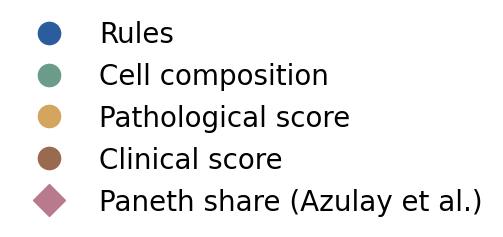

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\rule_classes.pdf


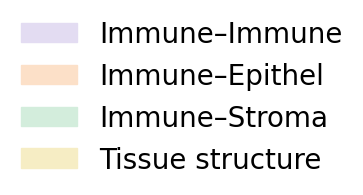

In [4]:
references = pv.REFERENCES.values()
fv.save_group_key({"Rules": pv.RULES_COLOR, **{name: color for name, color, _ in references}},
                  FONT_SIZE, "prediction", markers={name: marker for name, _, marker in references})
fv.save_class_key(FONT_SIZE)

## Both groups right

A row per predictor, best first: the best rule run, and the best run of each reference: cell composition, the pathological and the clinical score alone, and the Paneth share. Left: % of responders (filled) and of non-responders (hollow) predicted right; the dashed line is guessing. Right: their average, the % right, as a bar from 50% (guessing).

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\prediction_cortico_response_no_muscle_rules_both_groups\prediction_cortico_response_no_muscle_rules_both_groups.pdf
saved panel_1, panel_2 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\prediction_cortico_response_no_muscle_rules_both_groups


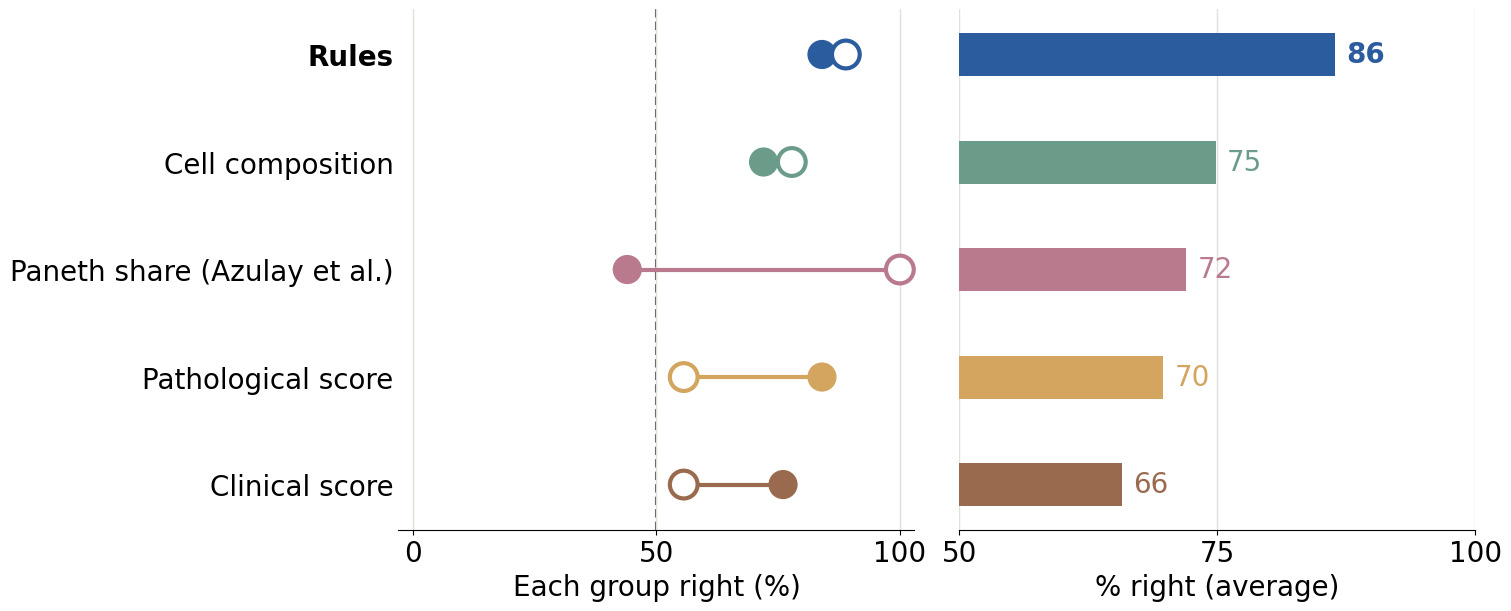

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\prediction_cortico_response_no_muscle_rules_both_groups\groups.pdf


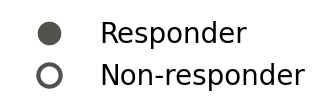

,rule_set,feature,min_patients,model,n_features,balanced_accuracy,auc,positive_right,negative_right
45,"Attraction, pairwise",mean lift,0.3,Lasso logistic regression,18,86.4,88.4,84.0,88.9
93,"Attraction, all sizes",mean lift,0.3,Lasso logistic regression,18,86.4,88.9,84.0,88.9
124,"Attraction + avoidance, pairwise",share of FOVs,0.3,Ridge logistic regression,33,84.4,89.3,80.0,88.9
172,"Attraction + avoidance, all sizes",share of FOVs,0.3,Ridge logistic regression,33,84.4,89.3,80.0,88.9
1,Cell composition,NaN,NaN,Lasso logistic regression,31,74.9,70.7,72.0,77.8
15,Paneth share of epithelium,NaN,NaN,Azulay: 2 PCA + linear SVM,1,72.0,76.9,44.0,100.0
4,Pathological score only,NaN,NaN,Ridge logistic regression,1,69.8,46.7,84.0,55.6
8,Clinical score only,NaN,NaN,Ridge logistic regression,1,65.8,42.2,76.0,55.6


In [5]:
fv.plot_both_groups(runs, {reference: (name, color) for reference, (name, color, _) in pv.REFERENCES.items()},
                    pv.RULES_COLOR, width=WIDTH, font_size=FONT_SIZE, save=f"{NAME}_both_groups")
best = runs.loc[runs.groupby("rule_set")[SCORE].idxmax()]
best[["rule_set", "feature", "min_patients", "model", "n_features", SCORE, "auc", "positive_right",
      "negative_right"]].sort_values(SCORE, ascending=False).round(1)

## The rules the best run leans on

The weights of the best run, fitted once on all patients. It was given the rules found in at least 30% of the patients; the rules it set to 0 are left out.

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\prediction_cortico_response_no_muscle_rules_weights\weights.pdf


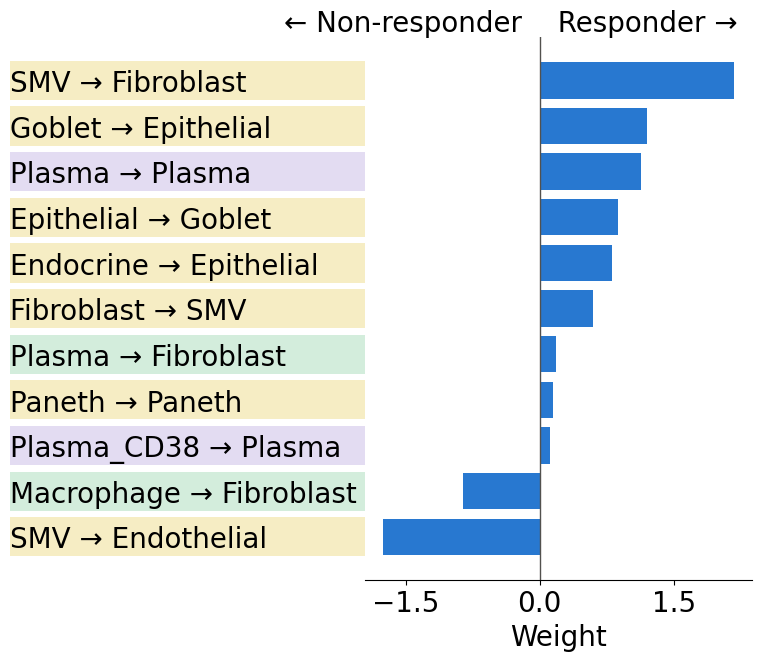

In [6]:
rules, kinds = zip(*weights["rule"].map(pv.plain_rule))
fv.plot_rule_weights(pd.Series(weights["weight"].to_numpy(), index=rules), dict(zip(rules, kinds)),
                     (first["negative"], first["positive"]), width=WIDTH, font_size=FONT_SIZE,
                     classes=dh.rule_class(list(rules), df_cells), save=f"{NAME}_weights")

## Real or luck

The best % right of the whole rule search on the real labels (line), against its best on each of 100 shufflings of the labels among the patients. p = the share of searches at least as good as the real one.

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\prediction_cortico_response_no_muscle_rules_permutation\permutation.pdf


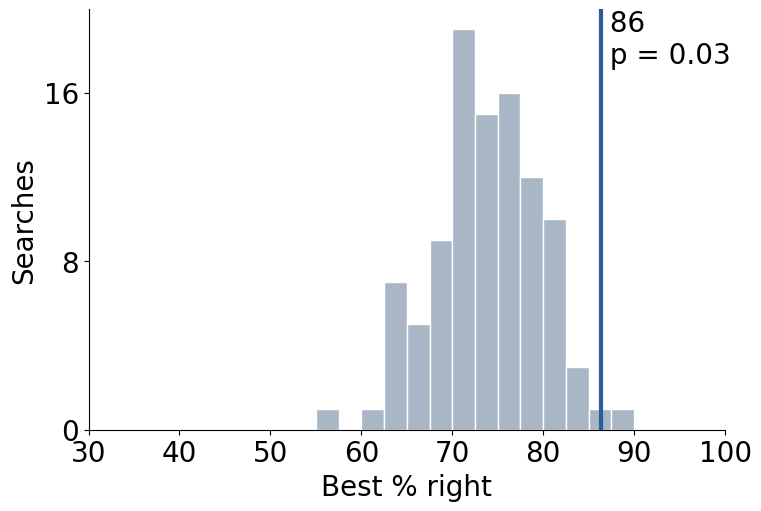

In [7]:
real = searches["real"]
fv.plot_permutation(searches.loc[~real, SCORE], searches.loc[real, SCORE].iloc[0], ps.p_value(searches, SCORE),
                    "Best % right", pv.RUN_COLOR, pv.RULES_COLOR, width=WIDTH, font_size=FONT_SIZE,
                    save=f"{NAME}_permutation")